
# 00 — Audit Data Penelitian

Notebook ini adalah tahap pertama sebelum seluruh simulasi machine learning.

Tujuan:
1. memahami struktur dataset mentah;
2. memastikan unit observasi, target, dan identifier jelas;
3. mengaudit kualitas data;
4. mendokumentasikan keputusan awal terhadap setiap fitur;
5. menghasilkan artefak audit yang menjadi acuan notebook berikutnya.

Notebook ini tidak melakukan pemodelan, tuning, resampling, atau SHAP.

`FINALTHRESHOLD` diperlakukan sebagai surrogate administrative label, bukan ground truth klinis kepatuhan aktual pasien.


### Prinsip penelitian
Notebook audit hanya mengidentifikasi struktur, kualitas, dan isu semantik data.
Tidak ada keputusan yang dibuat berdasarkan performa model dan tidak ada held-out test yang digunakan.


In [1]:

# CELL 1 - LIBRARY DAN KONFIGURASI

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

print("Audit data dimulai.")


Audit data dimulai.


In [2]:

# CELL 2 - PROJECT PATH

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Folder 'dataset' tidak ditemukan. Pastikan notebook berada "
        "di root project atau folder 'simulasi'."
    )

DATASET_DIR = PROJECT_ROOT / "dataset"
OUTPUT_DIR = PROJECT_ROOT / "output" / "00_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_candidates = sorted(DATASET_DIR.glob("Cimas*.csv"))

if not csv_candidates:
    raise FileNotFoundError(
        f"Dataset CIMAS tidak ditemukan pada folder: {DATASET_DIR}"
    )

DATA_PATH = csv_candidates[0]

print("PROJECT ROOT :", PROJECT_ROOT)
print("DATASET      :", DATA_PATH)
print("OUTPUT       :", OUTPUT_DIR)


PROJECT ROOT : /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent
DATASET      : /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/dataset/Cimas NCD Patient and  Medical Claims Data Medication Adherence Final.csv
OUTPUT       : /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/output/00_audit


## 1. Load data mentah

In [3]:

# CELL 3 - LOAD RAW DATA

df_raw = pd.read_csv(DATA_PATH)

print("Shape data mentah :", df_raw.shape)
print("Jumlah baris      :", len(df_raw))
print("Jumlah kolom      :", len(df_raw.columns))

print("\nDaftar kolom:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {col}")

display(df_raw.head())


Shape data mentah : (8142, 16)
Jumlah baris      : 8142
Jumlah kolom      : 16

Daftar kolom:
01. BENEFICIARY
02. YEAR
03. Diagnosis
04. AGE
05. AGEGROUP
06. SCHEMETYPE
07. HOSPITALCOVERTYPE
08. ANNUALCONTRIBUTION
09. WELLNESSPROGRAM
10. GENDER
11. ANNUALCLAIMAMOUNT
12. FINALTHRESHOLD
13. COMPLICATIONDVELOPMENT
14. COMORBIDITY
15. COMORBIDITY.1
16. UNITS


,BENEFICIARY,YEAR,Diagnosis,AGE,AGEGROUP,SCHEMETYPE,HOSPITALCOVERTYPE,ANNUALCONTRIBUTION,WELLNESSPROGRAM,GENDER,ANNUALCLAIMAMOUNT,FINALTHRESHOLD,COMPLICATIONDVELOPMENT,COMORBIDITY,COMORBIDITY.1,UNITS
0,3260976114,2022,Diabetes,16,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,MALE,219.65,ADHERENT,YES,NO,NO,69
1,3958374122,2022,Diabetes,16,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,928.35,ADHERENT,YES,NO,NO,397
2,3130974113,2022,Diabetes,17,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,581.64,NON-ADHERENT,YES,NO,NO,418
3,3278475122,2022,Diabetes,17,16-20,MEDIUMLEVEL,PRIVATE_GRADEA,900,SUBSCRIBED,FEMALE,328.61,NON-ADHERENT,NO,NO,NO,21
4,3395816142,2022,Diabetes,17,16-20,MEDIUMLEVEL,BASIC_TO_GRADEB,768,NOT_SUBSCRIBED,FEMALE,210.93,NON-ADHERENT,YES,YES,YES,42


## 2. Audit struktur dan baris non-observasi

In [4]:

# CELL 4 - STRUCTURAL AUDIT

year_numeric = pd.to_numeric(df_raw["YEAR"], errors="coerce")
non_observation_mask = year_numeric.isna()

non_observation_rows = df_raw.loc[non_observation_mask].copy()

print("Baris non-observasi/header terdeteksi:",
      int(non_observation_mask.sum()))

if len(non_observation_rows) > 0:
    display(non_observation_rows)

df = df_raw.loc[~non_observation_mask].copy()

print("\nShape audit view:", df.shape)


Baris non-observasi/header terdeteksi: 1


,BENEFICIARY,YEAR,Diagnosis,AGE,AGEGROUP,SCHEMETYPE,HOSPITALCOVERTYPE,ANNUALCONTRIBUTION,WELLNESSPROGRAM,GENDER,ANNUALCLAIMAMOUNT,FINALTHRESHOLD,COMPLICATIONDVELOPMENT,COMORBIDITY,COMORBIDITY.1,UNITS
1680,BENEFICIARY,YEAR,Diagnosis,AGE,AGEGROUP,SCHEMETYPE,HOSPITALCOVERTYPE,ANNUALCONTRIBUTION,WELLNESSPROGRAM,GENDER,ANNUALCLAIMAMOUNT,FINALTHRESHOLD,COMPLICATIONDVELOPMENT,COMORBIDITY,COMORBIDITY,UNITS



Shape audit view: (8141, 16)


## 3. Audit tipe data

In [5]:

# CELL 5 - DATA TYPE AUDIT

numeric_expected = [
    "YEAR",
    "AGE",
    "ANNUALCONTRIBUTION",
    "ANNUALCLAIMAMOUNT",
    "UNITS"
]

for col in numeric_expected:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

dtype_audit = pd.DataFrame({
    "column": df.columns,
    "dtype_after_audit_conversion": [str(df[c].dtype) for c in df.columns],
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    "missing": [df[c].isna().sum() for c in df.columns]
})

display(dtype_audit)


,column,dtype_after_audit_conversion,n_unique,missing
0,BENEFICIARY,str,6940,0
1,YEAR,int64,1,0
2,Diagnosis,str,2,0
3,AGE,int64,81,0
4,AGEGROUP,str,5,0
5,SCHEMETYPE,str,3,0
6,HOSPITALCOVERTYPE,str,3,0
7,ANNUALCONTRIBUTION,int64,8,0
8,WELLNESSPROGRAM,str,2,0
9,GENDER,str,2,5


## 4. Audit duplikasi

In [6]:

# CELL 6 - DUPLICATE AUDIT

exact_duplicate_count = int(df.duplicated().sum())

print("Exact duplicate rows:", exact_duplicate_count)

if exact_duplicate_count > 0:
    display(df[df.duplicated(keep=False)])


Exact duplicate rows: 0


## 5. Audit target FINALTHRESHOLD

In [7]:

# CELL 7 - TARGET AUDIT

TARGET = "FINALTHRESHOLD"

target_missing = int(df[TARGET].isna().sum())
target_counts = df[TARGET].value_counts(dropna=False)

print("Missing target:", target_missing)
print("\nDistribusi target:")
display(target_counts.rename_axis("label").reset_index(name="count"))

expected_labels = {"NON-ADHERENT", "ADHERENT"}
actual_labels = set(df[TARGET].dropna().astype(str).unique())
unexpected_labels = actual_labels - expected_labels

print("Label aktual    :", actual_labels)
print("Label unexpected:", unexpected_labels)

n_non_adherent = int((df[TARGET] == "NON-ADHERENT").sum())
n_adherent = int((df[TARGET] == "ADHERENT").sum())

imbalance_ratio = (
    n_non_adherent / n_adherent
    if n_adherent > 0 else np.nan
)

class_distribution = pd.DataFrame({
    "label": ["NON-ADHERENT", "ADHERENT"],
    "count": [n_non_adherent, n_adherent]
})

class_distribution["percentage"] = (
    class_distribution["count"] / len(df) * 100
)

print("\nImbalance Ratio (majority/minority):",
      round(imbalance_ratio, 4))

display(class_distribution.round(4))


Missing target: 0

Distribusi target:


,label,count
0,NON-ADHERENT,6600
1,ADHERENT,1541


Label aktual    : {'ADHERENT', 'NON-ADHERENT'}
Label unexpected: set()

Imbalance Ratio (majority/minority): 4.2829


,label,count,percentage
0,NON-ADHERENT,6600,81.0711
1,ADHERENT,1541,18.9289


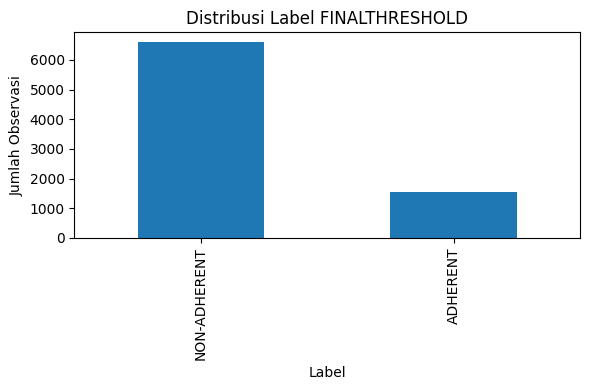

Saved: /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/output/00_audit/class_distribution.png


In [8]:

# VISUALISASI DISTRIBUSI KELAS

fig, ax = plt.subplots(figsize=(6, 4))

class_distribution.set_index("label")["count"].plot(
    kind="bar",
    ax=ax,
    legend=False
)

ax.set_title("Distribusi Label FINALTHRESHOLD")
ax.set_xlabel("Label")
ax.set_ylabel("Jumlah Observasi")

plt.tight_layout()

CLASS_PLOT_PATH = OUTPUT_DIR / "class_distribution.png"
plt.savefig(CLASS_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CLASS_PLOT_PATH)


## 6. Audit BENEFICIARY sebagai grouping ID

In [9]:

# CELL 8 - BENEFICIARY / GROUP AUDIT

GROUP_COL = "BENEFICIARY"

beneficiary_counts = (
    df.groupby(GROUP_COL)
      .size()
      .rename("n_observations")
      .reset_index()
)

n_unique_beneficiary = beneficiary_counts[GROUP_COL].nunique()
n_repeated_beneficiary = int(
    (beneficiary_counts["n_observations"] > 1).sum()
)
max_obs_per_beneficiary = int(
    beneficiary_counts["n_observations"].max()
)

label_per_beneficiary = (
    df.groupby(GROUP_COL)[TARGET]
      .nunique(dropna=True)
      .rename("n_unique_labels")
      .reset_index()
)

beneficiary_audit = beneficiary_counts.merge(
    label_per_beneficiary,
    on=GROUP_COL,
    how="left"
)

n_beneficiary_multiple_labels = int(
    (beneficiary_audit["n_unique_labels"] > 1).sum()
)

print("Jumlah BENEFICIARY unik         :", n_unique_beneficiary)
print("BENEFICIARY dengan >1 observasi :", n_repeated_beneficiary)
print("Maks observasi per BENEFICIARY  :", max_obs_per_beneficiary)
print("BENEFICIARY dengan >1 label     :", n_beneficiary_multiple_labels)

display(
    beneficiary_audit["n_observations"]
    .value_counts()
    .sort_index()
    .rename_axis("observations_per_beneficiary")
    .reset_index(name="n_beneficiaries")
)


Jumlah BENEFICIARY unik         : 6940
BENEFICIARY dengan >1 observasi : 1201
Maks observasi per BENEFICIARY  : 2
BENEFICIARY dengan >1 label     : 113


,observations_per_beneficiary,n_beneficiaries
0,1,5739
1,2,1201


## 7. Audit missing value

In [10]:

# CELL 9 - MISSING VALUE AUDIT

missing_values = pd.DataFrame({
    "column": df.columns,
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_percentage": [
        float(df[c].isna().mean() * 100)
        for c in df.columns
    ]
})

missing_values = missing_values.sort_values(
    "missing_count",
    ascending=False
).reset_index(drop=True)

display(missing_values)


,column,missing_count,missing_percentage
0,GENDER,5,0.061418
1,BENEFICIARY,0,0.000000
2,YEAR,0,0.000000
3,Diagnosis,0,0.000000
4,AGE,0,0.000000
5,AGEGROUP,0,0.000000
6,SCHEMETYPE,0,0.000000
7,HOSPITALCOVERTYPE,0,0.000000
8,ANNUALCONTRIBUTION,0,0.000000
9,WELLNESSPROGRAM,0,0.000000


## 8. Audit fitur konstan dan cardinality

In [11]:

# CELL 10 - CONSTANT / CARDINALITY AUDIT

feature_profile = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "n_unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns]
})

feature_profile["is_constant"] = feature_profile["n_unique"] <= 1

display(feature_profile)

constant_features = feature_profile.loc[
    feature_profile["is_constant"],
    "column"
].tolist()

print("Fitur konstan:", constant_features)


,column,dtype,n_unique,missing_count,is_constant
0,BENEFICIARY,str,6940,0,False
1,YEAR,int64,1,0,True
2,Diagnosis,str,2,0,False
3,AGE,int64,81,0,False
4,AGEGROUP,str,5,0,False
5,SCHEMETYPE,str,3,0,False
6,HOSPITALCOVERTYPE,str,3,0,False
7,ANNUALCONTRIBUTION,int64,8,0,False
8,WELLNESSPROGRAM,str,2,0,False
9,GENDER,str,2,5,False


Fitur konstan: ['YEAR']


## 9. Audit nilai kategorikal

In [12]:

# CELL 11 - CATEGORICAL LEVEL AUDIT

categorical_candidates = [
    "Diagnosis",
    "AGEGROUP",
    "SCHEMETYPE",
    "HOSPITALCOVERTYPE",
    "WELLNESSPROGRAM",
    "GENDER",
    "COMPLICATIONDVELOPMENT",
    "COMORBIDITY",
    "COMORBIDITY.1",
    "FINALTHRESHOLD"
]

categorical_records = []

for col in categorical_candidates:
    if col not in df.columns:
        continue

    vc = df[col].value_counts(dropna=False)

    for value, count in vc.items():
        categorical_records.append({
            "column": col,
            "value": value,
            "count": int(count)
        })

categorical_levels = pd.DataFrame(categorical_records)

display(categorical_levels)


,column,value,count
0,Diagnosis,Hypetension,6461
1,Diagnosis,Diabetes,1680
2,AGEGROUP,40-60,4271
3,AGEGROUP,60-80,2102
4,AGEGROUP,20-40,1434
5,AGEGROUP,81+,311
6,AGEGROUP,16-20,23
7,SCHEMETYPE,MEDIUMLEVEL,5180
8,SCHEMETYPE,PREMIUMLEVEL,1508
9,SCHEMETYPE,BASICLEVEL,1453


## 10. Audit numerik

In [13]:

# CELL 12 - NUMERIC SUMMARY

numeric_for_audit = [
    c for c in numeric_expected
    if c in df.columns
]

numeric_summary = (
    df[numeric_for_audit]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "column"})
)

display(numeric_summary)


,column,count,mean,std,min,25%,50%,75%,max
0,YEAR,8141.0,2022.000000,0.000000,2022.0,2022.00,2022.0,2022.00,2022.00
1,AGE,8141.0,52.684437,13.848089,16.0,43.00,52.0,62.00,101.00
2,ANNUALCONTRIBUTION,8141.0,3205.938337,7306.594019,84.0,768.00,768.0,900.00,25452.00
3,ANNUALCLAIMAMOUNT,8141.0,222.077724,1127.757009,0.1,21.53,68.5,193.49,40324.87
4,UNITS,8141.0,362.723007,461.270668,1.0,90.00,216.0,480.00,13140.00


## 11. Audit hubungan struktural antar atribut

In [14]:

# CELL 13 - STRUCTURAL / SEMANTIC CHECKS

if {"COMORBIDITY", "COMORBIDITY.1"}.issubset(df.columns):
    comorbidity_crosstab = pd.crosstab(
        df["COMORBIDITY"],
        df["COMORBIDITY.1"],
        dropna=False
    )

    print("Cross-tab COMORBIDITY vs COMORBIDITY.1")
    display(comorbidity_crosstab)
else:
    comorbidity_crosstab = pd.DataFrame()

if {"AGE", "AGEGROUP"}.issubset(df.columns):
    agegroup_summary = (
        df.groupby("AGEGROUP", dropna=False)["AGE"]
          .agg(["count", "min", "max", "mean"])
          .reset_index()
    )

    print("\nRingkasan AGE berdasarkan AGEGROUP")
    display(agegroup_summary)
else:
    agegroup_summary = pd.DataFrame()


Cross-tab COMORBIDITY vs COMORBIDITY.1


COMORBIDITY.1,NO,YES
COMORBIDITY,,
NO,479,0
YES,5260,2402



Ringkasan AGE berdasarkan AGEGROUP


,AGEGROUP,count,min,max,mean
0,16-20,23,16,19,17.347826
1,20-40,1434,20,39,33.530683
2,40-60,4271,40,59,49.909155
3,60-80,2102,60,79,67.174120
4,81+,311,80,101,83.794212



## 12. Audit unit observasi

Tahap ini digunakan untuk memahami **grain** atau unit empiris setiap baris.

Kita tidak langsung menyimpulkan satu baris = satu pasien. Audit memeriksa apakah kombinasi
`BENEFICIARY + YEAR + Diagnosis` unik dan atribut apa saja yang dapat berubah pada pasien yang sama.

Hasil ini menjadi dasar untuk:
- penggunaan `BENEFICIARY` sebagai grouping variable;
- interpretasi satu observasi pada tahap modeling;
- pencegahan kebocoran antar-observasi pasien yang sama.


In [15]:

# ============================================================
# CELL 14 - UNIT OF ANALYSIS AUDIT
# ============================================================

candidate_key = [
    "BENEFICIARY",
    "YEAR",
    "Diagnosis"
]

candidate_key_duplicate_rows = int(
    df.duplicated(
        subset=candidate_key
    ).sum()
)

beneficiary_observation_distribution = (
    df.groupby("BENEFICIARY")
      .size()
      .value_counts()
      .sort_index()
      .rename_axis("observations_per_beneficiary")
      .reset_index(name="n_beneficiaries")
)

repeated_ids = (
    beneficiary_counts.loc[
        beneficiary_counts["n_observations"] > 1,
        "BENEFICIARY"
    ]
)

repeated_df = df[
    df["BENEFICIARY"].isin(repeated_ids)
].copy()

diagnoses_per_repeated_beneficiary = (
    repeated_df.groupby("BENEFICIARY")["Diagnosis"]
               .nunique(dropna=True)
)

# Berapa pasien berulang yang memiliki tepat dua diagnosis berbeda?
n_repeated_with_two_diagnoses = int(
    (diagnoses_per_repeated_beneficiary == 2).sum()
)

# Audit atribut yang berubah pada pasien yang sama
variation_records = []

for col in df.columns:

    if col == "BENEFICIARY":
        continue

    n_unique_within = (
        repeated_df
        .groupby("BENEFICIARY")[col]
        .nunique(dropna=False)
    )

    n_beneficiaries_with_variation = int(
        (n_unique_within > 1).sum()
    )

    variation_records.append({
        "column": col,
        "repeated_beneficiaries_with_variation":
            n_beneficiaries_with_variation,
        "percentage_of_repeated_beneficiaries":
            (
                n_beneficiaries_with_variation
                / len(repeated_ids)
                * 100
                if len(repeated_ids) > 0
                else np.nan
            )
    })

within_beneficiary_variation = pd.DataFrame(
    variation_records
).sort_values(
    "repeated_beneficiaries_with_variation",
    ascending=False
).reset_index(drop=True)

unit_of_analysis_summary = pd.DataFrame([{
    "valid_rows": len(df),
    "unique_beneficiaries":
        int(df["BENEFICIARY"].nunique()),
    "repeated_beneficiaries":
        int(len(repeated_ids)),
    "candidate_key":
        "BENEFICIARY + YEAR + Diagnosis",
    "candidate_key_duplicate_rows":
        candidate_key_duplicate_rows,
    "repeated_beneficiaries_with_two_diagnoses":
        n_repeated_with_two_diagnoses
}])

print("Candidate empirical key:",
      "BENEFICIARY + YEAR + Diagnosis")

print(
    "Duplicate berdasarkan candidate key:",
    candidate_key_duplicate_rows
)

print(
    "BENEFICIARY berulang dengan 2 diagnosis:",
    n_repeated_with_two_diagnoses,
    "dari",
    len(repeated_ids)
)

print("\nDistribusi observasi per BENEFICIARY:")
display(beneficiary_observation_distribution)

print("\nAtribut yang berubah pada BENEFICIARY berulang:")
display(
    within_beneficiary_variation.round(4)
)


Candidate empirical key: BENEFICIARY + YEAR + Diagnosis
Duplicate berdasarkan candidate key: 0
BENEFICIARY berulang dengan 2 diagnosis: 1201 dari 1201

Distribusi observasi per BENEFICIARY:


,observations_per_beneficiary,n_beneficiaries
0,1,5739
1,2,1201



Atribut yang berubah pada BENEFICIARY berulang:


,column,repeated_beneficiaries_with_variation,percentage_of_repeated_beneficiaries
0,Diagnosis,1201,100.0000
1,UNITS,1121,93.3389
2,COMPLICATIONDVELOPMENT,314,26.1449
3,FINALTHRESHOLD,113,9.4088
4,AGE,89,7.4105
5,AGEGROUP,3,0.2498
6,YEAR,0,0.0000
7,SCHEMETYPE,0,0.0000
8,HOSPITALCOVERTYPE,0,0.0000
9,ANNUALCONTRIBUTION,0,0.0000



## 13. Audit BENEFICIARY dengan lebih dari satu label

Audit sebelumnya menunjukkan sebagian `BENEFICIARY` mempunyai lebih dari satu nilai
`FINALTHRESHOLD`.

Tahap ini tidak menganggap salah satu label sebagai benar atau salah. Tujuannya adalah
mengetahui **pola perbedaan label menurut diagnosis**.

Hal ini relevan karena label merupakan indikator administratif pada level observasi,
bukan ground truth klinis pada level pasien.


In [16]:

# ============================================================
# CELL 15 - MULTIPLE LABEL BENEFICIARY AUDIT
# ============================================================

multiple_label_ids = (
    beneficiary_audit.loc[
        beneficiary_audit["n_unique_labels"] > 1,
        "BENEFICIARY"
    ]
)

multiple_label_rows = df[
    df["BENEFICIARY"].isin(
        multiple_label_ids
    )
].copy()

# Gunakan nama diagnosis yang distandardisasi hanya untuk pelaporan audit
multiple_label_rows["Diagnosis_Audit"] = (
    multiple_label_rows["Diagnosis"]
    .replace({
        "Hypetension": "Hypertension"
    })
)

# Pivot label per diagnosis untuk setiap beneficiary
multiple_label_pivot = (
    multiple_label_rows
    .pivot_table(
        index="BENEFICIARY",
        columns="Diagnosis_Audit",
        values="FINALTHRESHOLD",
        aggfunc="first"
    )
    .reset_index()
)

# Ringkasan kombinasi label Diabetes vs Hypertension
if {
    "Diabetes",
    "Hypertension"
}.issubset(multiple_label_pivot.columns):

    label_pair_summary = (
        multiple_label_pivot
        .groupby(
            [
                "Diabetes",
                "Hypertension"
            ],
            dropna=False
        )
        .size()
        .reset_index(name="n_beneficiaries")
        .sort_values(
            "n_beneficiaries",
            ascending=False
        )
        .reset_index(drop=True)
    )

else:
    label_pair_summary = pd.DataFrame()

print(
    "Jumlah BENEFICIARY dengan >1 label:",
    len(multiple_label_ids)
)

if not label_pair_summary.empty:
    print(
        "\nPola label berbeda menurut diagnosis:"
    )
    display(label_pair_summary)

# Detail lokal disimpan untuk audit, tidak perlu ditampilkan seluruhnya.
multiple_label_detail = (
    multiple_label_rows[
        [
            "BENEFICIARY",
            "YEAR",
            "Diagnosis_Audit",
            "FINALTHRESHOLD",
            "AGE",
            "COMPLICATIONDVELOPMENT",
            "UNITS"
        ]
    ]
    .sort_values(
        [
            "BENEFICIARY",
            "Diagnosis_Audit"
        ]
    )
)


Jumlah BENEFICIARY dengan >1 label: 113

Pola label berbeda menurut diagnosis:


,Diabetes,Hypertension,n_beneficiaries
0,NON-ADHERENT,ADHERENT,64
1,ADHERENT,NON-ADHERENT,49



## 14. Audit konsistensi AGE dan AGEGROUP

`AGE` dan `AGEGROUP` merepresentasikan konsep umur dalam bentuk berbeda.

Audit ini tidak langsung mengubah `AGEGROUP`. Kita hanya memeriksa batas empiris setiap kategori
dan menandai ketidaksesuaian yang perlu dijelaskan dari dokumentasi dataset.


In [17]:

# ============================================================
# CELL 16 - AGE / AGEGROUP CONSISTENCY AUDIT
# ============================================================

agegroup_empirical_bounds = (
    df.groupby(
        "AGEGROUP",
        dropna=False
    )["AGE"]
    .agg(
        count="count",
        min_age="min",
        max_age="max",
        mean_age="mean"
    )
    .reset_index()
)

display(
    agegroup_empirical_bounds.round(4)
)

# Flag khusus berdasarkan temuan empiris:
# label "81+" ternyata memuat AGE = 80.
age_80_in_81plus = int(
    (
        (df["AGEGROUP"] == "81+")
        &
        (df["AGE"] == 80)
    ).sum()
)

agegroup_review = pd.DataFrame([
    {
        "issue":
            "AGEGROUP '81+' contains AGE=80",
        "affected_rows":
            age_80_in_81plus,
        "status":
            (
                "REVIEW_REQUIRED"
                if age_80_in_81plus > 0
                else "NO_FLAG"
            ),
        "action":
            (
                "Jangan diubah otomatis. "
                "Konfirmasi definisi AGEGROUP dari dokumentasi sumber."
            )
    }
])

print(
    "Jumlah observasi AGE=80 pada AGEGROUP='81+':",
    age_80_in_81plus
)

display(agegroup_review)

# Tambahan: AGE dapat berubah pada beneficiary berulang.
age_variation_repeated = (
    repeated_df
    .groupby("BENEFICIARY")["AGE"]
    .agg(
        min_age="min",
        max_age="max"
    )
)

age_variation_repeated[
    "age_difference"
] = (
    age_variation_repeated["max_age"]
    -
    age_variation_repeated["min_age"]
)

age_variation_summary = pd.DataFrame([{
    "repeated_beneficiaries_with_age_difference":
        int(
            (
                age_variation_repeated[
                    "age_difference"
                ] > 0
            ).sum()
        ),
    "maximum_age_difference":
        float(
            age_variation_repeated[
                "age_difference"
            ].max()
        )
}])

print("\nAGE variation pada BENEFICIARY berulang:")
display(age_variation_summary)


,AGEGROUP,count,min_age,max_age,mean_age
0,16-20,23,16,19,17.3478
1,20-40,1434,20,39,33.5307
2,40-60,4271,40,59,49.9092
3,60-80,2102,60,79,67.1741
4,81+,311,80,101,83.7942


Jumlah observasi AGE=80 pada AGEGROUP='81+': 46


,issue,affected_rows,status,action
0,AGEGROUP '81+' contains AGE=80,46,REVIEW_REQUIRED,Jangan diubah otomatis. Konfirmasi definisi AG...



AGE variation pada BENEFICIARY berulang:


,repeated_beneficiaries_with_age_difference,maximum_age_difference
0,89,1.0



## 15. Audit plausibilitas dan distribusi numerik

Tahap ini **tidak menghapus outlier**.

Kita hanya mendokumentasikan:
- rentang;
- persentil;
- nilai nol/negatif;
- jumlah observasi yang terflag oleh aturan IQR.

Flag IQR adalah indikator distribusi, **bukan bukti bahwa nilai tersebut salah**.
Keputusan transformasi atau penghapusan data tidak dilakukan pada tahap audit ini.


In [18]:

# ============================================================
# CELL 17 - NUMERIC PLAUSIBILITY AUDIT
# ============================================================

numeric_audit_columns = [
    "AGE",
    "ANNUALCONTRIBUTION",
    "ANNUALCLAIMAMOUNT",
    "UNITS"
]

numeric_plausibility_records = []

for col in numeric_audit_columns:

    s = df[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_iqr = q1 - 1.5 * iqr
    upper_iqr = q3 + 1.5 * iqr

    iqr_flag_count = int(
        (
            (s < lower_iqr)
            |
            (s > upper_iqr)
        ).sum()
    )

    numeric_plausibility_records.append({
        "column": col,
        "count": int(s.count()),
        "min": float(s.min()),
        "p01": float(s.quantile(0.01)),
        "p05": float(s.quantile(0.05)),
        "p25": float(q1),
        "median": float(s.median()),
        "p75": float(q3),
        "p95": float(s.quantile(0.95)),
        "p99": float(s.quantile(0.99)),
        "max": float(s.max()),
        "negative_count": int((s < 0).sum()),
        "zero_count": int((s == 0).sum()),
        "iqr_lower_bound": float(lower_iqr),
        "iqr_upper_bound": float(upper_iqr),
        "iqr_flag_count": iqr_flag_count,
        "iqr_flag_percentage":
            float(iqr_flag_count / len(s) * 100)
    })

numeric_plausibility = pd.DataFrame(
    numeric_plausibility_records
)

display(
    numeric_plausibility.round(4)
)

print(
    "\nCATATAN: IQR flag tidak dihapus otomatis."
)


,column,count,min,p01,p05,p25,median,p75,p95,p99,max,negative_count,zero_count,iqr_lower_bound,iqr_upper_bound,iqr_flag_count,iqr_flag_percentage
0,AGE,8141,16.0,24.000,31.00,43.00,52.0,62.00,78.00,86.00,101.00,0,0,14.50,90.50,17,0.2088
1,ANNUALCONTRIBUTION,8141,84.0,84.000,360.00,768.00,768.0,900.00,25452.00,25452.00,25452.00,0,0,570.00,1098.00,2961,36.3715
2,ANNUALCLAIMAMOUNT,8141,0.1,0.874,3.42,21.53,68.5,193.49,720.01,1607.78,40324.87,0,0,-236.41,451.43,876,10.7603
3,UNITS,8141,1.0,2.000,28.00,90.00,216.0,480.00,1196.00,1892.00,13140.00,0,0,-495.00,1065.00,530,6.5103



CATATAN: IQR flag tidak dihapus otomatis.


## 16. Research decision register

In [19]:

# CELL 14 - FEATURE ROLE REGISTER

initial_roles = {
    "BENEFICIARY": {
        "role": "GROUP_ID",
        "decision": "EXCLUDE_FROM_PREDICTOR",
        "reason": "Identifier pasien; digunakan untuk group-aware splitting."
    },
    "FINALTHRESHOLD": {
        "role": "TARGET",
        "decision": "TARGET_ONLY",
        "reason": "Surrogate administrative label ADHERENT/NON-ADHERENT."
    },
    "YEAR": {
        "role": "CANDIDATE_EXCLUDE",
        "decision": "EXCLUDE_IF_CONSTANT",
        "reason": "Tidak membawa informasi diskriminatif apabila seluruh nilai sama."
    },
    "UNITS": {
        "role": "PREDICTOR",
        "decision": "KEEP_MAIN_ANALYSIS",
        "reason": "Dipertahankan pada main analysis; diuji lagi pada sensitivity analysis."
    },
    "ANNUALCLAIMAMOUNT": {
        "role": "PREDICTOR",
        "decision": "KEEP_MAIN_ANALYSIS",
        "reason": "Dipertahankan pada main analysis; diuji lagi pada sensitivity analysis."
    },
    "COMORBIDITY.1": {
        "role": "PREDICTOR_REVIEW",
        "decision": "KEEP_PENDING_SEMANTIC_REVIEW",
        "reason": "Tidak dihapus otomatis sebelum makna semantiknya dikonfirmasi."
    }
}

default_predictors = [
    "Diagnosis",
    "AGE",
    "AGEGROUP",
    "SCHEMETYPE",
    "HOSPITALCOVERTYPE",
    "ANNUALCONTRIBUTION",
    "WELLNESSPROGRAM",
    "GENDER",
    "COMPLICATIONDVELOPMENT",
    "COMORBIDITY"
]

for col in default_predictors:
    initial_roles[col] = {
        "role": "PREDICTOR",
        "decision": "KEEP_CANDIDATE",
        "reason": "Kandidat predictor; keputusan final mengikuti audit kualitas dan protokol penelitian."
    }

feature_role_rows = []

for col in df.columns:
    info = initial_roles.get(
        col,
        {
            "role": "REVIEW",
            "decision": "REVIEW",
            "reason": "Belum diklasifikasikan."
        }
    )

    feature_role_rows.append({
        "column": col,
        "role": info["role"],
        "decision": info["decision"],
        "reason": info["reason"],
        "n_unique": int(df[col].nunique(dropna=True)),
        "missing_count": int(df[col].isna().sum()),
        "is_constant": bool(df[col].nunique(dropna=True) <= 1)
    })

feature_roles = pd.DataFrame(feature_role_rows)

mask_year = feature_roles["column"].eq("YEAR")

if mask_year.any() and bool(
    feature_roles.loc[mask_year, "is_constant"].iloc[0]
):
    feature_roles.loc[mask_year, "decision"] = "EXCLUDE"
    feature_roles.loc[mask_year, "reason"] = (
        "Fitur konstan pada dataset audit sehingga tidak memiliki variasi diskriminatif."
    )

display(feature_roles)


,column,role,decision,reason,n_unique,missing_count,is_constant
0,BENEFICIARY,GROUP_ID,EXCLUDE_FROM_PREDICTOR,Identifier pasien; digunakan untuk group-aware...,6940,0,False
1,YEAR,CANDIDATE_EXCLUDE,EXCLUDE,Fitur konstan pada dataset audit sehingga tida...,1,0,True
2,Diagnosis,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,2,0,False
3,AGE,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,81,0,False
4,AGEGROUP,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,5,0,False
5,SCHEMETYPE,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,3,0,False
6,HOSPITALCOVERTYPE,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,3,0,False
7,ANNUALCONTRIBUTION,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,8,0,False
8,WELLNESSPROGRAM,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,2,0,False
9,GENDER,PREDICTOR,KEEP_CANDIDATE,Kandidat predictor; keputusan final mengikuti ...,2,5,False


## 17. Aturan cleaning statis

In [20]:

# CELL 15 - STATIC CLEANING RULES

cleaning_rules = pd.DataFrame([
    {
        "column": "DATASET",
        "issue": "Repeated header / non-observation row",
        "rule": "Hapus baris ketika YEAR tidak dapat dikonversi menjadi numerik.",
        "reason": "Baris tersebut bukan observasi pasien."
    },
    {
        "column": "Diagnosis",
        "issue": "Typographical inconsistency",
        "rule": "Hypetension -> Hypertension",
        "reason": "Standardisasi penulisan kategori yang sama."
    },
    {
        "column": "HOSPITALCOVERTYPE",
        "issue": "Capitalization inconsistency",
        "rule": "Basic_TO_GradeB -> BASIC_TO_GRADEB",
        "reason": "Mencegah kategori identik dibaca sebagai kategori berbeda."
    },
    {
        "column": "GENDER",
        "issue": "Missing value",
        "rule": "Tangani di dalam preprocessing pipeline pada training fold.",
        "reason": "Mencegah informasi validation/test digunakan pada imputasi."
    }
])

display(cleaning_rules)


,column,issue,rule,reason
0,DATASET,Repeated header / non-observation row,Hapus baris ketika YEAR tidak dapat dikonversi...,Baris tersebut bukan observasi pasien.
1,Diagnosis,Typographical inconsistency,Hypetension -> Hypertension,Standardisasi penulisan kategori yang sama.
2,HOSPITALCOVERTYPE,Capitalization inconsistency,Basic_TO_GradeB -> BASIC_TO_GRADEB,Mencegah kategori identik dibaca sebagai kateg...
3,GENDER,Missing value,Tangani di dalam preprocessing pipeline pada t...,Mencegah informasi validation/test digunakan p...


## 18. Structural-overlap register

In [21]:

# CELL 16 - STRUCTURAL OVERLAP REGISTER

structural_overlap_review = pd.DataFrame([
    {
        "feature": "UNITS",
        "status": "REVIEW_IN_SENSITIVITY",
        "reason": (
            "Agregat tahunan penggunaan/pasokan medis dan berada pada periode "
            "yang sama dengan pembentukan indikator kepatuhan."
        ),
        "action": "Pertahankan pada main analysis; uji perubahan performa ketika fitur dikeluarkan."
    },
    {
        "feature": "ANNUALCLAIMAMOUNT",
        "status": "REVIEW_IN_SENSITIVITY",
        "reason": (
            "Agregat tahunan nilai klaim dan berada pada periode "
            "yang sama dengan pembentukan indikator kepatuhan."
        ),
        "action": "Pertahankan pada main analysis; uji perubahan performa ketika fitur dikeluarkan."
    }
])

display(structural_overlap_review)


,feature,status,reason,action
0,UNITS,REVIEW_IN_SENSITIVITY,Agregat tahunan penggunaan/pasokan medis dan b...,Pertahankan pada main analysis; uji perubahan ...
1,ANNUALCLAIMAMOUNT,REVIEW_IN_SENSITIVITY,Agregat tahunan nilai klaim dan berada pada pe...,Pertahankan pada main analysis; uji perubahan ...


## 19. Research gate sebelum baseline

In [22]:

# ============================================================
# CELL 21 - RESEARCH GATE CHECK
# ============================================================

technical_gate_checks = {
    "valid_observations_known":
        len(df) > 0,

    "target_has_no_missing":
        target_missing == 0,

    "target_labels_expected":
        len(unexpected_labels) == 0,

    "beneficiary_available":
        GROUP_COL in df.columns,

    "candidate_empirical_key_has_no_duplicates":
        candidate_key_duplicate_rows == 0,

    "feature_roles_defined":
        len(feature_roles) == len(df.columns),

    "cleaning_rules_documented":
        len(cleaning_rules) > 0
}

technical_gate_table = pd.DataFrame({
    "check":
        list(
            technical_gate_checks.keys()
        ),
    "passed":
        list(
            technical_gate_checks.values()
        )
})

technical_gate_passed = bool(
    technical_gate_table["passed"].all()
)

# Semantic review tidak berarti dataset gagal.
# Ini menunjukkan ada atribut/definisi yang masih perlu dikonfirmasi.
semantic_review_items = pd.DataFrame([
    {
        "item":
            "Unit observasi",
        "status":
            "REVIEW_REQUIRED",
        "reason":
            (
                "Secara empiris BENEFICIARY+YEAR+Diagnosis unik, "
                "tetapi interpretasi semantik unit observasi "
                "tetap perlu dikonfirmasi dari dokumentasi sumber."
            )
    },
    {
        "item":
            "COMORBIDITY.1",
        "status":
            "REVIEW_REQUIRED",
        "reason":
            (
                "Hubungannya dengan COMORBIDITY terstruktur, "
                "tetapi arti atribut belum dipastikan dari dokumentasi."
            )
    },
    {
        "item":
            "AGEGROUP",
        "status":
            (
                "REVIEW_REQUIRED"
                if age_80_in_81plus > 0
                else "NO_FLAG"
            ),
        "reason":
            (
                "Kategori '81+' memuat AGE=80; "
                "jangan dikoreksi tanpa dokumentasi sumber."
            )
    }
])

semantic_review_required = bool(
    (
        semantic_review_items["status"]
        == "REVIEW_REQUIRED"
    ).any()
)

if not technical_gate_passed:
    overall_audit_status = (
        "TECHNICAL_REVIEW_REQUIRED"
    )

elif semantic_review_required:
    overall_audit_status = (
        "STRUCTURAL_AUDIT_COMPLETE - "
        "SEMANTIC_REVIEW_REQUIRED"
    )

else:
    overall_audit_status = (
        "READY_FOR_BASELINE_FREEZE"
    )

print("Technical Gate:")
display(technical_gate_table)

print("\nSemantic Review:")
display(semantic_review_items)

print(
    "\nSTATUS AUDIT:",
    overall_audit_status
)

# Dipertahankan agar cell penyimpanan lama tetap kompatibel
gate_table = technical_gate_table.copy()
gate_table["audit_status"] = overall_audit_status
all_passed = technical_gate_passed


Technical Gate:


,check,passed
0,valid_observations_known,True
1,target_has_no_missing,True
2,target_labels_expected,True
3,beneficiary_available,True
4,candidate_empirical_key_has_no_duplicates,True
5,feature_roles_defined,True
6,cleaning_rules_documented,True



Semantic Review:


,item,status,reason
0,Unit observasi,REVIEW_REQUIRED,Secara empiris BENEFICIARY+YEAR+Diagnosis unik...
1,COMORBIDITY.1,REVIEW_REQUIRED,"Hubungannya dengan COMORBIDITY terstruktur, te..."
2,AGEGROUP,REVIEW_REQUIRED,Kategori '81+' memuat AGE=80; jangan dikoreksi...



STATUS AUDIT: STRUCTURAL_AUDIT_COMPLETE - SEMANTIC_REVIEW_REQUIRED


## 20. Simpan seluruh artefak audit

In [23]:

# CELL 18 - SAVE AUDIT OUTPUTS

dataset_summary = pd.DataFrame([
    {
        "raw_rows": len(df_raw),
        "raw_columns": len(df_raw.columns),
        "non_observation_rows": int(non_observation_mask.sum()),
        "valid_rows": len(df),
        "valid_columns": len(df.columns),
        "exact_duplicate_rows": exact_duplicate_count,
        "unique_beneficiaries": n_unique_beneficiary,
        "beneficiaries_with_multiple_observations": n_repeated_beneficiary,
        "beneficiaries_with_multiple_labels": n_beneficiary_multiple_labels,
        "non_adherent_count": n_non_adherent,
        "adherent_count": n_adherent,
        "imbalance_ratio": imbalance_ratio
    }
])

dataset_summary.to_csv(
    OUTPUT_DIR / "dataset_summary.csv",
    index=False
)

class_distribution.to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    index=False
)

missing_values.to_csv(
    OUTPUT_DIR / "missing_values.csv",
    index=False
)

feature_profile.to_csv(
    OUTPUT_DIR / "feature_profile.csv",
    index=False
)

categorical_levels.to_csv(
    OUTPUT_DIR / "categorical_levels.csv",
    index=False
)

numeric_summary.to_csv(
    OUTPUT_DIR / "numeric_summary.csv",
    index=False
)

beneficiary_audit.to_csv(
    OUTPUT_DIR / "beneficiary_audit.csv",
    index=False
)

feature_roles.to_csv(
    OUTPUT_DIR / "feature_roles.csv",
    index=False
)

cleaning_rules.to_csv(
    OUTPUT_DIR / "cleaning_rules.csv",
    index=False
)

structural_overlap_review.to_csv(
    OUTPUT_DIR / "structural_overlap_review.csv",
    index=False
)

gate_table.to_csv(
    OUTPUT_DIR / "research_gate.csv",
    index=False
)

if not comorbidity_crosstab.empty:
    comorbidity_crosstab.to_csv(
        OUTPUT_DIR / "comorbidity_crosstab.csv"
    )

if not agegroup_summary.empty:
    agegroup_summary.to_csv(
        OUTPUT_DIR / "agegroup_summary.csv",
        index=False
    )


unit_of_analysis_summary.to_csv(
    OUTPUT_DIR / "unit_of_analysis_summary.csv",
    index=False
)

beneficiary_observation_distribution.to_csv(
    OUTPUT_DIR / "beneficiary_observation_distribution.csv",
    index=False
)

within_beneficiary_variation.to_csv(
    OUTPUT_DIR / "within_beneficiary_variation.csv",
    index=False
)

multiple_label_detail.to_csv(
    OUTPUT_DIR / "multiple_label_beneficiaries.csv",
    index=False
)

if not label_pair_summary.empty:
    label_pair_summary.to_csv(
        OUTPUT_DIR / "multiple_label_summary.csv",
        index=False
    )

agegroup_empirical_bounds.to_csv(
    OUTPUT_DIR / "agegroup_empirical_bounds.csv",
    index=False
)

agegroup_review.to_csv(
    OUTPUT_DIR / "agegroup_review.csv",
    index=False
)

age_variation_summary.to_csv(
    OUTPUT_DIR / "age_variation_summary.csv",
    index=False
)

numeric_plausibility.to_csv(
    OUTPUT_DIR / "numeric_plausibility.csv",
    index=False
)

technical_gate_table.to_csv(
    OUTPUT_DIR / "technical_gate.csv",
    index=False
)

semantic_review_items.to_csv(
    OUTPUT_DIR / "semantic_review.csv",
    index=False
)

print("Semua artefak audit tersimpan pada:")
print(OUTPUT_DIR)


Semua artefak audit tersimpan pada:
/Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/output/00_audit


## 21. Buat ringkasan audit untuk research log

In [24]:

# ============================================================
# CELL 23 - GENERATE AUDIT REPORT
# ============================================================

report_lines = [
    "# 00 Audit Data — Research Log",
    "",
    "## Dataset",
    f"- Raw rows: {len(df_raw)}",
    f"- Valid observations: {len(df)}",
    f"- Number of attributes: {len(df.columns)}",
    f"- Exact duplicate rows: {exact_duplicate_count}",
    "",
    "## Target",
    f"- NON-ADHERENT: {n_non_adherent}",
    f"- ADHERENT: {n_adherent}",
    f"- Imbalance ratio: {imbalance_ratio:.4f}:1",
    "- FINALTHRESHOLD diperlakukan sebagai surrogate administrative label.",
    "",
    "## Grouping dan unit observasi",
    f"- Unique BENEFICIARY: {n_unique_beneficiary}",
    f"- BENEFICIARY dengan >1 observasi: {n_repeated_beneficiary}",
    f"- BENEFICIARY dengan >1 label: {n_beneficiary_multiple_labels}",
    f"- Duplicate pada BENEFICIARY+YEAR+Diagnosis: {candidate_key_duplicate_rows}",
    f"- BENEFICIARY berulang dengan tepat 2 diagnosis: {n_repeated_with_two_diagnoses}",
    "- BENEFICIARY tidak digunakan sebagai predictor.",
    "- Group-aware splitting diperlukan pada tahap modeling.",
    "- Kombinasi BENEFICIARY+YEAR+Diagnosis merupakan candidate empirical key; interpretasi semantik tetap perlu dikonfirmasi.",
    "",
    "## Data quality",
    f"- Constant features: {', '.join(constant_features) if constant_features else 'None'}",
    f"- Columns with missing values: {', '.join(missing_values.loc[missing_values['missing_count'] > 0, 'column'].tolist()) or 'None'}",
    f"- AGE=80 pada AGEGROUP '81+': {age_80_in_81plus} observasi",
    "",
    "## Research decisions",
    "- YEAR dikeluarkan jika terbukti konstan.",
    "- Missing value ditangani di dalam pipeline, bukan sebelum split.",
    "- UNITS dan ANNUALCLAIMAMOUNT dipertahankan pada main analysis dan diuji pada sensitivity analysis.",
    "- COMORBIDITY.1 tidak dihapus otomatis; status semantiknya tetap dicatat untuk review.",
    "- IQR outlier hanya ditandai, tidak dihapus otomatis.",
    "- Tidak ada model machine learning yang dijalankan pada tahap audit.",
    "",
    "## Gate",
    f"- Technical gate passed: {technical_gate_passed}",
    f"- Overall status: {overall_audit_status}"
]

REPORT_PATH = (
    OUTPUT_DIR
    / "00_audit_report.md"
)

REPORT_PATH.write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

print(
    "Report saved:",
    REPORT_PATH
)

print("\n")
print(
    "\n".join(report_lines)
)


Report saved: /Users/riskyduha/Documents/Tesis/Prediction_Non_Adherent/output/00_audit/00_audit_report.md


# 00 Audit Data — Research Log

## Dataset
- Raw rows: 8142
- Valid observations: 8141
- Number of attributes: 16
- Exact duplicate rows: 0

## Target
- NON-ADHERENT: 6600
- ADHERENT: 1541
- Imbalance ratio: 4.2829:1
- FINALTHRESHOLD diperlakukan sebagai surrogate administrative label.

## Grouping dan unit observasi
- Unique BENEFICIARY: 6940
- BENEFICIARY dengan >1 observasi: 1201
- BENEFICIARY dengan >1 label: 113
- Duplicate pada BENEFICIARY+YEAR+Diagnosis: 0
- BENEFICIARY berulang dengan tepat 2 diagnosis: 1201
- BENEFICIARY tidak digunakan sebagai predictor.
- Group-aware splitting diperlukan pada tahap modeling.
- Kombinasi BENEFICIARY+YEAR+Diagnosis merupakan candidate empirical key; interpretasi semantik tetap perlu dikonfirmasi.

## Data quality
- Constant features: YEAR
- Columns with missing values: GENDER
- AGE=80 pada AGEGROUP '81+': 46 observasi

## Research decisi